<a href="https://colab.research.google.com/github/SithmiDesilva/Voices-on-School-Reform-An-NLP-Analysis-of-Sri-Lankan-YouTube-Comments/blob/Cleaning-and-tokenisation/Voices_on_School_Reform_An_NLP_Analysis_of_Sri_Lankan_YouTube_Comments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Task 1 - Video discovery, comment collection and initial exploration

**Study topic:** public YouTube discussion of Sri Lankan school education reforms (curriculum, O/L subject reduction, GPA/credit system, Grade 1 and Grade 6 modular reforms, teacher capacity, history and arts subjects, the textbook controversy).

**Data source:** public comments only, collected through the **YouTube Data API v3**. No web scraping, no video or audio transcription.

**Language scope:** **Sinhala and English only**, including romanised Sinhala ("Singlish") and Sinhala–English code-mixing. Tamil is excluded completely (Tamil-medium videos, Tamil-script comments and romanised Tamil). This keeps the later multilingual processing within languages that the author can read and validate by hand, which matters for the manual checks in Tasks 3, 5 and 6. The cost is that Tamil-speaking communities are not represented; this is treated as a limitation in Task 6.

**Privacy and data minimisation:** only the comment text and the metadata needed for analysis are stored. Author display names and profile URLs are never saved. Author channel IDs are replaced by a salted SHA-256 hash (the salt is kept in Colab Secrets), which still allows repeat-poster and spam checks without identifying anyone.

**Pipeline:** search → video details → relevance filtering (automatic + documented manual review) → comment collection with checkpoints → unmodified raw file → corpus construction (duplicates, off-topic videos, Tamil, 30% rule) → collection log → exploratory data analysis (EDA) on the raw comment text.

### Imports and Versions

In [30]:
import os, re, json, time, random, hashlib, math
from datetime import datetime, timezone
from pathlib import Path
from collections import Counter
from importlib.metadata import version
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from googleapiclient.discovery import build
from googleapiclient.errors import HttpError
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import warnings
warnings.filterwarnings('ignore', message='.*(Glyph|does not support Sinhala).*')

SEED = 42
random.seed(SEED); np.random.seed(SEED)

pd.set_option('display.max_colwidth', 120)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

print('Python                  ', sys.version.split()[0])
print('pandas                  ', pd.__version__)
print('numpy                   ', np.__version__)
print('matplotlib              ', matplotlib.__version__)
print('scikit-learn            ', sklearn.__version__)
print('google-api-python-client', version('google-api-python-client'))

Python                   3.13.16
pandas                   2.2.3
numpy                    2.4.6
matplotlib               3.10.0
scikit-learn             1.6.1
google-api-python-client 2.201.0


**Reproducibility.** A fixed random seed (42) is used for every sampling step, and package versions are printed above. `warnings` filters only hide matplotlib font messages caused by Sinhala and decorative characters in channel names; they do not hide any data problems.

### Mount Google drive

In [31]:
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR = Path('/content/drive/MyDrive/NLP_CW')
RAW_DIR  = BASE_DIR / 'data' / 'raw'
CKPT_DIR = RAW_DIR / 'comments_by_video'      # one JSON per video (checkpoint)
FIG_DIR  = BASE_DIR / 'figures'
for d in (RAW_DIR, CKPT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
print(BASE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/NLP_CW


### API client

In [32]:
from google.colab import userdata
YT_API_KEY = userdata.get('YT_API_KEY')
youtube = build('youtube', 'v3', developerKey=YT_API_KEY, cache_discovery=False)

try:
    AUTHOR_SALT = userdata.get('AUTHOR_SALT')
except Exception:
    AUTHOR_SALT = 'change-me-and-store-in-secrets'
print('YouTube client ready')

YouTube client ready


### Search queries and settings

In [33]:
SEARCH_QUERIES = {
    'en': [
        'Sri Lanka education reform',
        'Sri Lanka new education reforms 2026',
        'Sri Lanka school curriculum change',
        'Sri Lanka O/L A/L exam reform',
        'Sri Lanka grade 1 grade 6 new curriculum',
        'Sri Lanka education reform teachers',
        'Sri Lanka modular education system school',
        'Sri Lanka vocational education schools reform',
        'Sri Lanka digital education schools',
        'Sri Lanka history subject removed curriculum',
        'Sri Lanka education minister reform debate',
    ],
    'si': [
        'අධ්‍යාපන ප්‍රතිසංස්කරණ',
        'නව අධ්‍යාපන ප්‍රතිසංස්කරණ',
        'අධ්‍යාපන ප්‍රතිසංස්කරණ ගුරුවරු',
        'නව විෂය නිර්දේශය පාසල්',
        'සාමාන්‍ය පෙළ උසස් පෙළ වෙනස්කම්',
        '6 ශ්‍රේණිය මොඩියුල',
        'පළමු ශ්‍රේණිය නව ප්‍රතිසංස්කරණ',
        'adyapana prathisanskarana',       # romanised Sinhala ("Singlish")
    ],
}

PUBLISHED_AFTER = '2024-01-01T00:00:00Z'   # current reform cycle
REGION_CODE = 'LK'
RESULTS_PER_QUERY = 25          # max 50 per search call
MIN_COMMENT_COUNT = 15          # skip videos with very few comments
MAX_COMMENTS_PER_VIDEO = 800    # per-video ceiling (30% rule applied later)
INCLUDE_REPLIES = True
FETCH_ALL_REPLIES = True        # commentThreads gives only 5 inline replies; fetch the rest
COMMENT_ORDER = 'time'          # avoids YouTube's relevance ranking
MAX_VIDEO_SHARE = 0.30
TARGET_MIN_COMMENTS = 3000

RELEVANCE_KEYWORDS = [
    'education', 'reform', 'curriculum', 'syllabus', 'school', 'exam', 'o/l', 'a/l', 'grade', 'teacher',
    'module', 'vocational', 'student',
    'අධ්‍යාපන', 'ප්‍රතිසංස්කරණ', 'විෂය', 'පාසල', 'ගුරු', 'ශ්‍රේණිය', 'පෙළ', 'විභාග', 'මොඩියුල', 'සිසු',
]
SRI_LANKA_KEYWORDS = ['sri lanka', 'srilanka', 'lanka', 'ශ්‍රී ලංකා', 'ලංකා', 'harini', 'හරිනි']

COLLECTION_DATE = datetime.now(timezone.utc).isoformat()
print('Total queries:', sum(len(v) for v in SEARCH_QUERIES.values()))

Total queries: 19


**Search design.** 19 queries were used: 11 in English and 8 in Sinhala (one of them romanised Sinhala), covering several reform areas rather than one controversy: curriculum and syllabus change, O/L and A/L exam reform, Grade 1 and Grade 6 changes, teachers, modular education, vocational and digital education, the history subject, and the political debate.

Key settings and why:
- `PUBLISHED_AFTER = 2024-01-01`: restricts results to the current reform cycle.
- `REGION_CODE = 'LK'` and `relevanceLanguage`: biases results towards Sri Lankan content in each language.
- `MIN_COMMENT_COUNT = 15`: videos with very few comments cost API calls but add almost no data.
- `MAX_COMMENTS_PER_VIDEO = 800` and `COMMENT_ORDER = 'time'`: limits the influence of very large videos and avoids depending on YouTube's own "top comments" ranking.
- Replies are included, because much of the disagreement happens in reply threads.

### Quota-aware API wrapper

In [34]:
QUOTA_COST = {'search': 100, 'videos': 1, 'commentThreads': 1, 'comments': 1}
quota_used = Counter()

class QuotaExceeded(Exception):
    pass

def http_reason(e):
    try:
        return json.loads(e.content.decode())['error']['errors'][0]['reason']
    except Exception:
        return f'http_{getattr(e.resp, "status", "unknown")}'

def api_call(request, kind, max_retries=4):
    for attempt in range(max_retries):
        try:
            resp = request.execute()
            quota_used[kind] += QUOTA_COST[kind]
            return resp
        except HttpError as e:
            quota_used[kind] += QUOTA_COST[kind]
            reason = http_reason(e)
            if reason in ('quotaExceeded', 'dailyLimitExceeded'):
                raise QuotaExceeded(reason)
            if e.resp.status in (500, 502, 503, 504) and attempt < max_retries - 1:
                time.sleep(2 ** attempt)
                continue
            raise

def quota_total():
    return sum(quota_used.values())

**API quota handling.** The default quota is 10,000 units per day; a search costs 100 units, while video, comment-thread and reply requests cost 1 unit each. Every call goes through `api_call`, which counts units, retries temporary server errors (HTTP 5xx) with exponential back-off, and stops cleanly when the daily quota is exhausted so that collection can resume the next day.

### Search for videos (results cached to Drive)

In [35]:
SEARCH_CACHE = RAW_DIR / 'search_cache.json'
search_cache = json.loads(SEARCH_CACHE.read_text()) if SEARCH_CACHE.exists() else {}

def search_videos(query, lang):
    key = f'{lang}|{query}'
    if key in search_cache:
        return search_cache[key]
    req = youtube.search().list(
        q=query, part='snippet', type='video', maxResults=min(RESULTS_PER_QUERY, 50),
        regionCode=REGION_CODE, relevanceLanguage=lang,
        publishedAfter=PUBLISHED_AFTER, order='relevance')
    resp = api_call(req, 'search')
    rows = [{
        'query': query, 'query_lang': lang,
        'video_id': it['id']['videoId'],
        'title': it['snippet']['title'],
        'channel_id': it['snippet']['channelId'],
        'channel_title': it['snippet']['channelTitle'],
        'video_published_at': it['snippet']['publishedAt'],
        'searched_at': datetime.now(timezone.utc).isoformat(),
    } for it in resp.get('items', [])]
    search_cache[key] = rows
    SEARCH_CACHE.write_text(json.dumps(search_cache, ensure_ascii=False, indent=1))
    return rows

hits = []
for lang, queries in SEARCH_QUERIES.items():
    for q in queries:
        hits.extend(search_videos(q, lang))

search_df = pd.DataFrame(hits)
print(f'{len(search_df)} hits, {search_df.video_id.nunique()} unique videos, quota used: {quota_total()}')
search_df.groupby('query_lang').video_id.nunique()

475 hits, 306 unique videos, quota used: 0


,video_id
query_lang,
en,197
si,121


Search results are cached in `search_cache.json` on Drive, so re-running the notebook re-uses them instead of spending quota again (this is why quota used shows 0 on re-runs). The 19 queries returned **475 hits for 306 unique videos** (197 from English queries, 121 from Sinhala queries; some videos were found by both).

### Video details (comment counts, descriptions)


In [36]:
cand = (search_df.groupby('video_id')
        .agg(title=('title', 'first'), channel_id=('channel_id', 'first'),
             channel_title=('channel_title', 'first'), video_published_at=('video_published_at', 'first'),
             matched_queries=('query', lambda s: ' || '.join(sorted(set(s)))),
             query_langs=('query_lang', lambda s: ','.join(sorted(set(s)))))
        .reset_index())

# Cache video details on Drive so comment counts (and therefore the video selection)
# stay fixed across re-runs. Delete video_details.json only to deliberately refresh.
DETAILS_CACHE = RAW_DIR / 'video_details.json'
if DETAILS_CACHE.exists():
    details = json.loads(DETAILS_CACHE.read_text())
    print('Loaded cached video details (no API calls)')
else:
    details = []
    ids = cand.video_id.tolist()
    for i in range(0, len(ids), 50):
        resp = api_call(youtube.videos().list(part='snippet,statistics', id=','.join(ids[i:i+50])), 'videos')
        for it in resp.get('items', []):
            st, sn = it.get('statistics', {}), it['snippet']
            details.append({
                'video_id': it['id'],
                'description': sn.get('description', ''),
                'tags': '|'.join(sn.get('tags', [])),
                'default_audio_language': sn.get('defaultAudioLanguage'),
                'view_count': int(st.get('viewCount', 0)),
                'comment_count': int(st['commentCount']) if 'commentCount' in st else None,
            })
    DETAILS_CACHE.write_text(json.dumps(details, ensure_ascii=False, indent=1))
    print('Fetched and cached video details')

videos = cand.merge(pd.DataFrame(details), on='video_id', how='left')
print('Videos with comments disabled/unavailable:', videos.comment_count.isna().sum())

Fetched and cached video details
Videos with comments disabled/unavailable: 11


Full details (comment count, description, tags) are fetched in batches of 50 video IDs, which costs only 1 unit per batch. When `commentCount` is missing from the statistics, comments are disabled: **11 videos** fell into this group and were excluded.

### Relevance filter and manual review

In [37]:
def kw_hits(text, kws):
    t = str(text).lower()
    return sum(k.lower() in t for k in kws)

meta_text = videos.title.fillna('') + ' ' + videos.description.fillna('') + ' ' + videos.tags.fillna('')
videos['topic_kw_hits'] = meta_text.apply(lambda t: kw_hits(t, RELEVANCE_KEYWORDS))
videos['lk_kw_hits'] = meta_text.apply(lambda t: kw_hits(t, SRI_LANKA_KEYWORDS))
videos['local_query'] = videos.query_langs.str.contains('si')

videos['exclusion_reason'] = np.select(
    [videos.comment_count.isna(),
     videos.comment_count < MIN_COMMENT_COUNT,
     videos.topic_kw_hits == 0,
     (videos.lk_kw_hits == 0) & ~videos.local_query],
    ['comments_disabled_or_unavailable', 'too_few_comments', 'no_topic_keywords', 'not_sri_lanka'],
    default='')
videos['auto_include'] = videos.exclusion_reason == ''

# ---- Manual review: fill in after reading the titles below ----
MANUAL_EXCLUDE = {
    # Exclude general PM speech at summit
    'WbiLX0VRmF0': 'general speech by the PM at an NDTV summit, not focused on school reform',
    # Unrelated topic
    '4ii1rkZDhgI': 'geography/identity topic, not school reform',
    'j42KPskCsc0': 'motivational video (bad habits), not education reform',
    'K9yjfbOISnM': 'driving licence renewal, unrelated',
    'bzTQMZalVtM': 'Indian UPSC/degree debate, not Sri Lankan schools',
    # School rankings
    'h9nL4RwNAEE': 'school ranking (top 10 schools), not reform',
    'k7Y15uXnD_Y': 'school ranking (top 10 mixed schools), not reform',
    'C0ypaTw172w': 'school ranking (top 10 boys schools), not reform',
    'D9m0gq1sqcc': 'A/L subject ranking and results date, not reform',
    # Exam / certificate administration guides
    '1mGozsjkLYQ': 'how-to: A/L private application',
    'JwMy5pCk6i4': 'how-to: ordering result sheets',
    'hoUH6bmB9a8': 'how-to: certificate attestation',
    'NKp9ZXhANAU': 'how-to: certifying result sheets',
    'sCltsoIY0uY': 'how-to: downloading exam admission',
    'ZWP_SEiG21g': 'how-to: ordering certificates online',
    'A1RE63CYzH0': 'how-to: requesting certificates online',
    'xXCAP3jTeTo': 'how-to: certificate name correction',
    'P-0fBG3UaHM': 'how-to: Grade 1 admission application',
    'n4Pyhh_rg9M': 'A/L results release date announcement',
    'aRrFmhye2LE': 'O/L cut-off marks announcement',
    'JKwozF7VpTE': 'exam dates announcement',
    'SZ6tlaRiuPE': 'timetable software demo; comments request the software',
    'QcYm2EKhrC4': 'London vs national syllabus comparison; comments are contact requests',
    # Lessons (comments are thanks / class enquiries, not reform opinions)
    '-0pCTULWg8g': 'Grade 1 class promotion; comments are joining enquiries',
    'uHp107rDADk': 'Grade 6 module lesson',
    'aawhznhUzpU': 'Grade 6 module lesson',
    'xZ4WdYC_0qI': 'Grade 6 science lesson',
    'gC21s_wddnw': 'Grade 6 maths lesson',
    'o9l47fQZ6xI': 'Grade 6 maths lesson',
    'Fbw7Hg7s738': 'Grade 6 maths lesson',
    'BhQXKHDbNIs': 'Grade 6 English syllabus PDF download',
    'Xw0JGgmYHMc': 'Grade 1 Buddhism lesson',
    'i6jJgdZ8lvc': 'Sinhala grammar lesson',
    # Teaching-exam preparation (reforms as quiz content; comments are quiz answers)
    'ZYeuMI3SQzw': 'teaching-exam GK quiz on reforms; comments are quiz answers',
    'ioOFm7cYB7M': 'teaching-exam GK quiz on reforms; comments are quiz answers',
    'R9Onitso-Ic': 'teaching-exam preparation',
    'oVJKFQP9G6A': 'teaching-exam preparation',
    'mTKTus6XaWA': 'teaching-exam preparation (history of education)',
    # Tamil-medium videos (outside the Sinhala/English language scope)
    'FKoS8yJOKWo': 'Tamil-medium video; outside Sinhala/English scope',
    'sBUhUSix0qY': 'Tamil-medium video; outside Sinhala/English scope',
    'QQGkW9hedpU': 'Tamil-medium video; outside Sinhala/English scope',
    'spXSrrGSXuY': 'Tamil-medium video; outside Sinhala/English scope',
}
MANUAL_INCLUDE = {}   # {'videoId': 'reason'}
# ---------------------------------------------------------------
videos['include'] = videos.auto_include
for vid, why in MANUAL_EXCLUDE.items():
    videos.loc[videos.video_id == vid, ['include', 'exclusion_reason']] = [False, f'manual: {why}']
for vid, why in MANUAL_INCLUDE.items():
    videos.loc[videos.video_id == vid, ['include', 'exclusion_reason']] = [True, f'manual include: {why}']

videos.to_csv(RAW_DIR / 'videos_candidates.csv', index=False)
print(videos.exclusion_reason.replace('', 'included').value_counts(), "")
print('Included videos:', videos.include.sum(), '| channels:', videos.loc[videos.include, 'channel_id'].nunique())
videos.loc[videos.include, ['video_id', 'channel_title', 'title', 'comment_count', 'video_published_at']] \
      .sort_values('comment_count', ascending=False)

exclusion_reason
too_few_comments                                                                    194
included                                                                             32
not_sri_lanka                                                                        18
comments_disabled_or_unavailable                                                     11
no_topic_keywords                                                                     9
manual: Tamil-medium video; outside Sinhala/English scope                             4
manual: Grade 6 maths lesson                                                          3
manual: Grade 6 module lesson                                                         2
manual: teaching-exam GK quiz on reforms; comments are quiz answers                   2
manual: teaching-exam preparation                                                     2
manual: Grade 1 class promotion; comments are joining enquiries                       1
manual: how-to:

,video_id,channel_title,title,comment_count,video_published_at
75,F-DLnJM7jpg,Ada Derana,"O/L, A/L සහ ශිෂ්‍යත්ව විභාගය ගැන දැනුම්දීමක් | Ada Derana",1030.0,2026-06-24T10:37:50Z
141,RHfwHM3M9Fc,Ada Derana,අධ්‍යාපන ප්‍රතිසංස්කරණ ඇත්තටම අකුල ගත්තේ ඇයි | Ada Derana,845.0,2026-01-13T19:27:31Z
4,-pHFRz2p-Nw,Maths with Chathura Madushan,2026 O/L Syllabus Change – Subject 7යි Credit 18යි | අලුත් විෂය ක්‍රමය මෙන්න,728.0,2025-07-18T12:33:39Z
239,iKJSiiynAWQ,Hiru News,2026 සිට අධ්‍යාපනයට වෙන්න යන වෙනස - Hiru News,608.0,2025-01-23T09:30:54Z
173,WoD8P9g8OHs,BBC News සිංහල,නව අධ්‍යාපන ප්‍රතිසංස්කරණ සම්බන්ධයෙන් ජනාධිපති අනුර කුමාර දිසානායක පාර්ලිමේන්තුවේදී කළ ප්‍රකාශය,552.0,2025-07-24T07:58:24Z
154,Srr-sYiIDuI,BBC News සිංහල,නව අධ්‍යාපන ප්‍රතිසංස්කරණ සම්බන්ධයෙන් මාධ්‍යවේදීන් නැගූ ප්‍රශ්නවලට ලැබුණු පිළිතුරු | BBC News සිංහල,512.0,2025-07-23T13:16:27Z
296,wq5d9IPRnfk,Sigiri TV Online,Dr Nalinda Jayatissa | දෙරණ TV වාද පිටිය වැඩසටහන | NPP SriLanka Political @SigiriTVOnlineOfficial,217.0,2026-01-15T05:27:31Z
255,mFrc4QiqAXE,Siyatha TV,2027 සිට සා/පෙළට විෂයයන් 7යි,209.0,2026-09-15T01:49:57Z
285,tHmwGBt4k74,Anjana Udara,අධ්‍යාපන ප්‍රතිසංස්කරණයේ ලොකුම අඩුපාඩුව මෙන්න! මොනවද මේ වීඩියෝ ලින්ක් ?,203.0,2026-01-03T01:01:15Z
64,D02nj8GVQYA,Firstpost,Gay Website in School Syllabus Forces Sri Lanka to Delay Education Reforms | Firstpost Live | N18G,152.0,2026-01-14T11:06:23Z


**Video selection.** Selection had two stages.

*1. Automatic filter.* A video was kept only if comments were enabled, it had at least 15 comments, its title/description/tags contained an education or reform keyword, and it was linked to Sri Lanka (keyword or found by a Sinhala query). Of 306 candidates: 195 had too few comments, 18 were not about Sri Lanka, 11 had comments disabled and 9 had no topic keywords, leaving **73 videos**.

*2. Documented manual review.* The titles and sample comments of all 73 were read (see the printout below the raw-data cell). The rule applied was:
> **Keep** videos that report, explain or debate the reforms (news, explainers of the new system, discussion of the Grade 6 module controversy). **Exclude** videos whose comments are not opinions about the reforms: lessons, school or subject rankings, exam and certificate how-to guides, teaching-exam quiz videos, unrelated topics, and Tamil-medium videos (outside the language scope).

This removed **41 videos** (37 off-topic + 4 Tamil-medium), each with a recorded reason in `MANUAL_EXCLUDE`, leaving **32 videos from 21 channels**.

Two borderline videos were kept after checking their content: `F-DLnJM7jpg` (Ada Derana notice on O/L, A/L and scholarship exam changes) and `wq5d9IPRnfk` (televised debate with the Deputy Minister of Education), because both discuss the reforms directly. Manual review is subjective, so the full list of decisions is saved in `videos_candidates.csv` and the collection log.

### Comment-fetching functions

In [38]:
def hash_author(channel_id):
    if not channel_id:
        return None
    return hashlib.sha256((AUTHOR_SALT + channel_id).encode()).hexdigest()[:16]

def make_row(c, video_id, is_reply, parent_id):
    s = c['snippet']
    return {
        'comment_id': c['id'],
        'parent_id': parent_id,
        'is_reply': is_reply,
        'video_id': video_id,
        'text_original': s.get('textOriginal', s.get('textDisplay')),
        'like_count': s.get('likeCount'),
        'comment_published_at': s.get('publishedAt'),
        'comment_updated_at': s.get('updatedAt'),
        'author_hash': hash_author(s.get('authorChannelId', {}).get('value')),  # no names stored
    }

def fetch_all_replies(parent_id, video_id):
    out, token = [], None
    while True:
        resp = api_call(youtube.comments().list(part='snippet', parentId=parent_id, maxResults=100,
                                                pageToken=token, textFormat='plainText'), 'comments')
        out += [make_row(r, video_id, True, parent_id) for r in resp.get('items', [])]
        token = resp.get('nextPageToken')
        if not token:
            return out

def fetch_video_comments(video_id, max_comments=MAX_COMMENTS_PER_VIDEO):
    rows, token = [], None
    while len(rows) < max_comments:
        try:
            resp = api_call(youtube.commentThreads().list(
                part='snippet,replies', videoId=video_id, maxResults=100, pageToken=token,
                textFormat='plainText', order=COMMENT_ORDER), 'commentThreads')
        except HttpError as e:
            return rows, http_reason(e)      # e.g. commentsDisabled
        for item in resp.get('items', []):
            top = item['snippet']['topLevelComment']
            rows.append(make_row(top, video_id, False, None))
            n_rep = item['snippet'].get('totalReplyCount', 0)
            if INCLUDE_REPLIES and n_rep:
                inline = item.get('replies', {}).get('comments', [])
                if FETCH_ALL_REPLIES and n_rep > len(inline):
                    rows += fetch_all_replies(top['id'], video_id)
                else:
                    rows += [make_row(r, video_id, True, top['id']) for r in inline]
        token = resp.get('nextPageToken')
        if not token:
            break
    return rows, 'ok'

**What is collected per comment:** comment ID, parent ID (for replies), reply flag, video ID, original text (`textOriginal`, i.e. the text as typed, without HTML), like count, published and updated timestamps, and the hashed author ID.

**Replies:** `commentThreads.list` returns at most 5 replies per thread, so when a thread has more, all replies are fetched separately with `comments.list`.

**Deleted comments:** the API does not return deleted or held-for-review comments, so they cannot enter the corpus. This also means the corpus is a snapshot of what was visible on the collection date.

### Collect comments (resumable)

In [39]:
selected = videos[videos.include].sort_values('comment_count', ascending=False)
status_log = {}

try:
    for _, v in selected.iterrows():
        ck = CKPT_DIR / f'{v.video_id}.json'
        if ck.exists():
            status_log[v.video_id] = json.loads(ck.read_text())['status']
            continue
        rows, status = fetch_video_comments(v.video_id)
        ck.write_text(json.dumps({'video_id': v.video_id, 'status': status,
                                  'collected_at': datetime.now(timezone.utc).isoformat(),
                                  'comments': rows}, ensure_ascii=False))
        status_log[v.video_id] = status
        print(f'{v.video_id}  {status:<18} {len(rows):>5} comments   quota used: {quota_total()}')
except QuotaExceeded:
    print('Daily quota reached; checkpoints saved. Re-run this cell tomorrow to resume.')

print('Quota used this session:', dict(quota_used), '=', quota_total())

Quota used this session: {'videos': 7} = 7


Each video's comments are saved as a separate JSON checkpoint on Drive. Videos that already have a checkpoint are skipped, so the cell can be re-run after a quota stop or a Colab disconnect without losing data or repeating API calls. Any API error for a video (for example `commentsDisabled`) is recorded as that video's status in the collection log.

### Save the unmodified raw file

In [40]:
records = []
for ck in sorted(CKPT_DIR.glob('*.json')):
    d = json.loads(ck.read_text())
    for r in d['comments']:
        r['collected_at'] = d['collected_at']
        records.append(r)

raw = pd.DataFrame(records)
vid_meta = videos[['video_id', 'channel_id', 'channel_title', 'title', 'video_published_at', 'matched_queries']] \
           .rename(columns={'title': 'video_title'})
raw = raw.merge(vid_meta, on='video_id', how='left')
raw.to_csv(RAW_DIR / 'raw_comments.csv', index=False, encoding='utf-8-sig')   # never edited after this
print(raw.shape)
raw.head(500)

(12825, 15)


,comment_id,parent_id,is_reply,video_id,text_original,like_count,comment_published_at,comment_updated_at,author_hash,collected_at,channel_id,channel_title,video_title,video_published_at,matched_queries
0,UgxzwPiB2TauS3ZJNNZ4AaABAg,None,False,-0pCTULWg8g,Ane Teecha Dan barida ape babawa danna,0,2026-11-04T10:39:42Z,2026-11-04T10:39:42Z,1692ab2fb2c9c7dc,2026-11-20T09:17:40.519707+00:00,UC6Mn7YVeOwxI2h6usI1sO1Q,Schoooly App-හරි පුදුම ඉස්කෝලේ,2026 නව 1 ශ්‍රේණිය පන්තිය ආරම්භය!,2025-12-31T02:31:48Z,පළමු ශ්‍රේණිය නව ප්‍රතිසංස්කරණ
1,UgyfsK0A8bV52nudHHV4AaABAg,None,False,-0pCTULWg8g,Teacher ape baba 1 sereniye teacher clz ekata sambanda karaganna puluwanda,0,2026-10-29T02:41:36Z,2026-10-29T02:41:36Z,76cd7dd46cf7faf5,2026-11-20T09:17:40.519707+00:00,UC6Mn7YVeOwxI2h6usI1sO1Q,Schoooly App-හරි පුදුම ඉස්කෝලේ,2026 නව 1 ශ්‍රේණිය පන්තිය ආරම්භය!,2025-12-31T02:31:48Z,පළමු ශ්‍රේණිය නව ප්‍රතිසංස්කරණ
2,Ugx4-snGmG-yERJVvKV4AaABAg,None,False,-0pCTULWg8g,අපේ පුතාවත් සම්බන්ධ කරන්න කැමතියි ටීචර් ඔයා හරිම ලස්සනට උගන්වනවා තෙරුවන් සරණයි ටිච,0,2026-10-11T16:30:22Z,2026-10-11T16:30:22Z,c9ff2a64dfd4901a,2026-11-20T09:17:40.519707+00:00,UC6Mn7YVeOwxI2h6usI1sO1Q,Schoooly App-හරි පුදුම ඉස්කෝලේ,2026 නව 1 ශ්‍රේණිය පන්තිය ආරම්භය!,2025-12-31T02:31:48Z,පළමු ශ්‍රේණිය නව ප්‍රතිසංස්කරණ
3,UgzThGekDYmgBZe8lTB4AaABAg,None,False,-0pCTULWg8g,මේ ළමයින්ට මොන පන්තිද,1,2026-06-17T10:17:55Z,2026-06-17T10:17:55Z,daeb4003ebc0ebb7,2026-11-20T09:17:40.519707+00:00,UC6Mn7YVeOwxI2h6usI1sO1Q,Schoooly App-හරි පුදුම ඉස්කෝලේ,2026 නව 1 ශ්‍රේණිය පන්තිය ආරම්භය!,2025-12-31T02:31:48Z,පළමු ශ්‍රේණිය නව ප්‍රතිසංස්කරණ
4,UgzHRJI41skEsejDuOl4AaABAg,None,False,-0pCTULWg8g,ටිච ක්ලාස් එකට ජොයින් වෙින්න ඔනි.කොහොමද ?,1,2026-06-10T11:02:36Z,2026-06-10T11:02:36Z,6d67588bb5466981,2026-11-20T09:17:40.519707+00:00,UC6Mn7YVeOwxI2h6usI1sO1Q,Schoooly App-හරි පුදුම ඉස්කෝලේ,2026 නව 1 ශ්‍රේණිය පන්තිය ආරම්භය!,2025-12-31T02:31:48Z,පළමු ශ්‍රේණිය නව ප්‍රතිසංස්කරණ
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,Ugw6ftyK1VTVkBs53Wx4AaABAg,None,False,-pHFRz2p-Nw,තෝරගන්න විෂයන් ඇතුළෙ අනිවාර්ය කරන්න ඕන ඒව තියෙනවා සිංහල ආගම අයින් කරල IT අනිවාර්ය කරන්න තිබ්බෙ,1,2025-07-19T12:59:53Z,2025-07-19T12:59:53Z,3d324362f32d8540,2026-11-20T09:17:05.223558+00:00,UC_0nRvlMjooFAZEiMTkCglA,Maths with Chathura Madushan,2026 O/L Syllabus Change – Subject 7යි Credit 18යි | අලුත් විෂය ක්‍රමය මෙන්න,2025-07-18T12:33:39Z,නව විෂය නිර්දේශය පාසල්
496,Ugy78Su5UDXhUqG9RQV4AaABAg,None,False,-pHFRz2p-Nw,සෞන්දර්ය විෂය ඇතුලේ රසාස්වාදය තියෙයි ද ?,1,2025-07-19T12:56:03Z,2025-07-19T12:56:03Z,d34994a7407eb263,2026-11-20T09:17:05.223558+00:00,UC_0nRvlMjooFAZEiMTkCglA,Maths with Chathura Madushan,2026 O/L Syllabus Change – Subject 7යි Credit 18යි | අලුත් විෂය ක්‍රමය මෙන්න,2025-07-18T12:33:39Z,නව විෂය නිර්දේශය පාසල්
497,Ugy0D6B9hTiSEVrVNAh4AaABAg,None,False,-pHFRz2p-Nw,එතකොට සර් ජී.පී එක අනුව උසස් පෙළට කරන සබ්ජෙක්ට් එක තීරණය කරන්නේ කොහොමද,3,2025-07-19T12:14:35Z,2025-07-19T12:14:35Z,16c735fb8a624663,2026-11-20T09:17:05.223558+00:00,UC_0nRvlMjooFAZEiMTkCglA,Maths with Chathura Madushan,2026 O/L Syllabus Change – Subject 7යි Credit 18යි | අලුත් විෂය ක්‍රමය මෙන්න,2025-07-18T12:33:39Z,නව විෂය නිර්දේශය පාසල්
498,UgzuKOQw706QREXW4Rh4AaABAg,None,False,-pHFRz2p-Nw,Ithihasaya aniwarya nokara anagathe Sri Lankika daruwanta lak ithihasaya gana watahimak Nathan aparade,2,2025-07-19T12:12:10Z,2025-07-19T12:12:10Z,7e3bea2a616480ec,2026-11-20T09:17:05.223558+00:00,UC_0nRvlMjooFAZEiMTkCglA,Maths with Chathura Madushan,2026 O/L Syllabus Change – Subject 7යි Credit 18යි | අලුත් විෂය ක්‍රමය මෙන්න,2025-07-18T12:33:39Z,නව විෂය නිර්දේශය පාසල්


**Unmodified raw data file.** All checkpoints are combined into `raw_comments.csv` (**12,810 rows**). This file is never edited afterwards; every later step writes a new file. It is saved with `utf-8-sig` encoding so Sinhala text displays correctly when opened in Excel or Google Sheets.

The printout below supports the manual video review described above: for each candidate video it shows the channel, comment count, title and three example comments.

### Language / script detection

In [41]:
import nltk
nltk.download('words', quiet=True)
from nltk.corpus import words as nltk_words

SI_RE  = re.compile(r'[\u0D80-\u0DFF]')    # Sinhala block
TA_RE  = re.compile(r'[\u0B80-\u0BFF]')    # Tamil block (used only to remove Tamil)
LAT_RE = re.compile(r'[A-Za-z]')

EN_VOCAB = {w.lower() for w in nltk_words.words()} | set(ENGLISH_STOP_WORDS) | {
    'sri', 'lanka', 'lankan', 'ol', 'al', 'sir', 'madam', 'miss', 'pls', 'plz', 'ok', 'okay', 'thanks', 'thx',
    'govt', 'gov', 'grade', 'module', 'modules', 'syllabus', 'curriculum', 'online', 'exam', 'exams',
    'tuition', 'reforms', 'minister', 'ministry', 'youtube', 'video', 'videos'}

SINGLISH_MARKERS = {
    'mama', 'mata', 'mage', 'oya', 'oyage', 'oyata', 'oyala', 'api', 'ape', 'apita', 'uba', 'umba', 'bn', 'machan',
    'eka', 'ekak', 'ekata', 'eke', 'eken', 'meka', 'mekata', 'naha', 'nathi', 'nane', 'neda', 'nedda', 'nm',
    'ehenam', 'ehema', 'mehema', 'ithin', 'harida', 'karanna', 'karala', 'karana', 'yanna', 'yana', 'giya',
    'denna', 'dena', 'ganna', 'gena', 'kiyala', 'kiyla', 'kiyanne', 'kiyana', 'danna', 'dannawa', 'puluwan',
    'puluwn', 'puluwanda', 'balanna', 'liyana', 'liyanna', 'thiyenne', 'thiyena', 'thiyanawa', 'tiyenne',
    'wenna', 'wena', 'wenne', 'wage', 'vage', 'godak', 'hodai', 'mokada', 'mokakda', 'kohomada', 'kawda',
    'dang', 'thama', 'tama', 'walata', 'wala', 'ayata', 'ayta', 'lamai', 'lamainta', 'lamaynta', 'wela',
    'wenawa', 'karanawa', 'yanawa', 'innawa', 'inne', 'hithanne'}

# Romanised Tamil (Tamil typed in English letters). Words shared with Singlish are left out on purpose.
ROMANISED_TAMIL_MARKERS = {
    'panna', 'pannunga', 'pannalam', 'pannuvanga', 'pannanum', 'epdi', 'eppidi', 'eppadi', 'irukku', 'iruku',
    'irakka', 'irukkum', 'illai', 'illaya', 'vendum', 'venum', 'wenum', 'sollunga', 'solla', 'sollanum',
    'theriyuma', 'teriyuma', 'theriyala', 'theriyum', 'ungal', 'ungalidam', 'ungaluku', 'ungalukku',
    'nammakku', 'namakku', 'enakku', 'enaku', 'ennaku', 'avanga', 'ivanga', 'romba', 'varathu', 'varuma',
    'mudiyuma', 'mudiyathu', 'mudiyum', 'thambi', 'ponga', 'vanga', 'aagum', 'aaguma', 'kudunga',
    'vaanga', 'naanga', 'neenga', 'ippo', 'nanri', 'nandri', 'lusu'}

def tamil_reason(text):
    """'tamil_script', 'romanised_tamil', or None."""
    t = str(text) if pd.notna(text) else ''
    if TA_RE.search(t):
        return 'tamil_script'
    toks = [w for w in re.findall(r'[a-z]+', t.lower()) if len(w) > 1]
    m = sum(w in ROMANISED_TAMIL_MARKERS for w in toks)
    if m >= 2 or (m >= 1 and len(toks) <= 6):
        return 'romanised_tamil'
    return None

def is_english_word(w):
    return w in EN_VOCAB or any(w.endswith(s) and w[:-len(s)] in EN_VOCAB for s in ('s', 'es', 'ed', 'ing', 'ly'))

def language_group(text):
    t = str(text) if pd.notna(text) else ''
    n_si, n_lat = len(SI_RE.findall(t)), len(LAT_RE.findall(t))
    total = n_si + n_lat
    if total == 0:
        return 'no_letters (emoji/symbols/numbers)'
    si_share = n_si / total
    if 0.2 <= si_share <= 0.8:
        return 'mixed_sinhala_english'
    if si_share > 0.8:
        return 'sinhala'
    toks = [w for w in re.findall(r'[a-z]+', t.lower()) if len(w) > 1]
    if not toks:
        return 'english'
    en_ratio = sum(is_english_word(w) for w in toks) / len(toks)
    markers = sum(w in SINGLISH_MARKERS for w in toks)
    if markers >= 2 or (markers >= 1 and en_ratio < 0.8) or en_ratio < 0.5:
        return 'romanised_sinhala (singlish)'
    return 'english'

**Language and script detection.** Standard language detectors handle Sinhala poorly and do not recognise romanised Sinhala, which is very common in Sri Lankan comments, so a rule-based detector was written:

1. **Script share** using Unicode ranges (Sinhala U+0D80–U+0DFF, Latin A–Z). More than 80% Sinhala letters → `sinhala`; 20–80% → `mixed_sinhala_english`; no letters at all → `no_letters` (emoji, numbers).
2. For Latin-script comments, **English vs Singlish** is decided from (a) the share of tokens found in an English dictionary (NLTK `words` + common platform terms) and (b) a list of frequent Singlish function words (e.g. *eka, karanna, puluwan, thiyenne*).
3. **Tamil detection** (`tamil_reason`): any Tamil-script character, or romanised Tamil found by distinctive Tamil words (e.g. *panna, venum, irukku*). Words that also occur in Singlish were deliberately left out of the Tamil list.

This is a heuristic. Its accuracy is measured against a hand-labelled sample in the EDA section.

### Duplicates, Tamil exclusion, 30% rule

In [42]:
def enforce_video_cap(df, max_share=MAX_VIDEO_SHARE, seed=SEED):
    df = df.copy()
    rng = np.random.default_rng(seed)
    while True:
        counts = df.video_id.value_counts()
        cap = math.floor(max_share * len(df))
        over = counts[counts > cap]
        if over.empty:
            return df
        drop_idx = []
        for vid, n in over.items():
            idx = df.index[df.video_id == vid].to_numpy()
            drop_idx += list(rng.choice(idx, size=n - cap, replace=False))
        df = df.drop(index=drop_idx)

n0 = len(raw)
corpus = raw.drop_duplicates('comment_id').reset_index(drop=True)
n_dup_ids = n0 - len(corpus)

# Keep only videos that passed automatic + manual relevance review
keep_ids = set(videos.loc[videos.include, 'video_id'])
n_before = len(corpus)
corpus = corpus[corpus.video_id.isin(keep_ids)].reset_index(drop=True)
n_offtopic = n_before - len(corpus)

# Scope: Sinhala + English only. Remove ALL Tamil (any Tamil-script character, or romanised Tamil).
ta_reason = corpus.text_original.apply(tamil_reason)
tamil_removed = corpus[ta_reason.notna()].assign(reason=ta_reason)
tamil_removed[['comment_id', 'video_id', 'reason']].to_csv(RAW_DIR / 'tamil_removed_ids.csv', index=False)
n_tamil_script = int((ta_reason == 'tamil_script').sum())
n_tamil_roman = int((ta_reason == 'romanised_tamil').sum())
corpus = corpus[ta_reason.isna()].reset_index(drop=True)

n1 = len(corpus)
corpus = enforce_video_cap(corpus).reset_index(drop=True)
n_capped = n1 - len(corpus)

corpus.to_csv(RAW_DIR / 'corpus_selected_raw_text.csv', index=False, encoding='utf-8-sig')

share = corpus.video_id.value_counts(normalize=True)
checks = {
    'raw rows': n0,
    'duplicate comment IDs removed': n_dup_ids,
    'comments from excluded (off-topic / Tamil-medium) videos': n_offtopic,
    'Tamil-script comments removed': n_tamil_script,
    'romanised-Tamil comments removed': n_tamil_roman,
    'removed by 30% cap': n_capped,
    'final unique comments': len(corpus),
    'videos': corpus.video_id.nunique(),
    'channels': corpus.channel_id.nunique(),
    'largest video share': f'{share.max():.1%}',
    'meets >=3000 comments': len(corpus) >= TARGET_MIN_COMMENTS,
    'meets >=3 channels': corpus.channel_id.nunique() >= 3,
    'meets <=30% per video': bool(share.max() <= MAX_VIDEO_SHARE + 1e-9),
}
pd.Series(checks, name='value').to_frame()

,value
raw rows,12825
duplicate comment IDs removed,41
comments from excluded (off-topic / Tamil-medium) videos,6693
Tamil-script comments removed,6
romanised-Tamil comments removed,1
removed by 30% cap,0
final unique comments,6084
videos,32
channels,21
largest video share,17.0%


**Corpus construction.** Starting from 12,810 raw rows:

| Step | Removed | Reason |
|---|---|---|
| Duplicate comment IDs | 41 | The same comment returned twice (e.g. once inline, once via `comments.list`) |
| Excluded videos | 6,678 | Comments from the 41 off-topic or Tamil-medium videos |
| Tamil-script comments | 6 | Outside the Sinhala/English scope |
| Romanised-Tamil comments | 2 | Outside the Sinhala/English scope |
| 30% cap | 0 | No video exceeded 30%, so no downsampling was needed |

**Final corpus: 6,083 comments, 32 videos, 21 channels; the largest video holds 17.0%.** All three requirements (≥ 3,000 comments, ≥ 3 channels, ≤ 30% per video) are met.

The **30% rule** is enforced by `enforce_video_cap`, which would randomly (seed 42) remove comments from any over-represented video until it falls under 30%; it is kept in the pipeline so the rule is guaranteed even if the corpus changes.

**Deliberately not removed at this stage:** exact duplicate texts (e.g. copy-paste spam), emoji-only and very short comments. The spec asks for EDA *before* substantial preprocessing, so these are measured in the EDA below and removed in Task 2. Only the IDs of removed Tamil comments are saved (`tamil_removed_ids.csv`), not their text.

In [43]:
# Check that no Tamil remains, and inspect what the romanised-Tamil rule removed
print('Tamil characters left in corpus:', int(corpus.text_original.str.contains(r'[\u0B80-\u0BFF]').sum()))
print('\nRemoved as romanised Tamil:')
for t in tamil_removed.loc[tamil_removed.reason == 'romanised_tamil', 'text_original']:
    print(' -', t[:100])

Tamil characters left in corpus: 0

Removed as romanised Tamil:
 - Year a mention pannunga please


The check confirms that no Tamil-script characters remain. The romanised-Tamil comments removed are listed so the rule can be checked by hand.

### Collection log (for reproducibility)

In [44]:
log = {
    'collection_date_utc': COLLECTION_DATE,
    'api': 'YouTube Data API v3',
    'language_scope': 'Sinhala and English only (incl. romanised Sinhala and code-mixing); all Tamil removed: '
                      'Tamil-medium videos, any Tamil-script text, and romanised Tamil',
    'search_queries': SEARCH_QUERIES,
    'params': {k: globals()[k] for k in ['PUBLISHED_AFTER', 'REGION_CODE', 'RESULTS_PER_QUERY', 'MIN_COMMENT_COUNT',
                                         'MAX_COMMENTS_PER_VIDEO', 'INCLUDE_REPLIES', 'FETCH_ALL_REPLIES',
                                         'COMMENT_ORDER', 'MAX_VIDEO_SHARE', 'SEED']},
    'manual_exclude': MANUAL_EXCLUDE, 'manual_include': MANUAL_INCLUDE,
    'video_status': status_log,
    'quota_used_this_session': dict(quota_used),
    'counts': {k: str(v) for k, v in checks.items()},
}
(RAW_DIR / 'collection_log.json').write_text(json.dumps(log, ensure_ascii=False, indent=2, default=str))
print('Saved:', *[p.name for p in RAW_DIR.iterdir() if p.is_file()], sep='\n  ')

Saved:
  search_cache.json
  videos_candidates.csv
  raw_comments.csv
  tamil_removed_ids.csv
  corpus_selected_raw_text.csv
  collection_log.json
  video_details.json


**Collection log.** `collection_log.json` records everything needed to reproduce the corpus: collection date, the exact search queries, all parameters, every manual include/exclude decision with its reason, each video's collection status, quota used and the final counts. Together with `raw_comments.csv` (comment IDs, video IDs, channel IDs, publication dates) this satisfies the reproducibility requirement.

## EDA

### Add language and length columns

In [45]:
corpus['lang_group'] = corpus.text_original.apply(language_group)
corpus['n_chars'] = corpus.text_original.fillna('').str.len()
corpus['n_words'] = corpus.text_original.fillna('').str.split().str.len()
corpus['comment_published_at'] = pd.to_datetime(corpus.comment_published_at, utc=True)
corpus['comment_updated_at'] = pd.to_datetime(corpus.comment_updated_at, utc=True)

Language group, character count and word count are added to each comment for the EDA. Timestamps are converted to timezone-aware datetimes. No text is changed.

In [46]:
lang_counts = corpus.lang_group.value_counts()
print('=== New Language Group Distribution ===')
display(lang_counts.to_frame('count'))

print('\n=== Random Classification Samples ===')
for group in lang_counts.index:
    print(f'\n--- Group: {group} ---')
    samples = corpus[corpus.lang_group == group].sample(min(5, lang_counts[group]), random_state=SEED)['text_original'].tolist()
    for i, s in enumerate(samples, 1):
        print(f'{i}. {repr(s)}')

=== New Language Group Distribution ===


,count
lang_group,
sinhala,2952
romanised_sinhala (singlish),1609
english,752
mixed_sinhala_english,386
no_letters (emoji/symbols/numbers),385



=== Random Classification Samples ===

--- Group: sinhala ---
1. '1වසර 6වසර ව්තරක් නෙමෙයි.අනික් ළමයි  ගැනත් හිතුවා නම්  වට්නවා.ඔවුන් පීඩනයෙන් පරණ ව්දිහටම.'
2. 'අවුරුදු අද 18 ක විතර දරුවෙක් ඉන්න අම්මාකෙනෙක් නොගන්නා තිරනයක් .අද ජංගම දුරකතන මගින් දරුවෝ නාස්ති නරකට යොමු වෙනවා ඒක ටිකක් හෝ අඩු වෙලා තියෙන්නෙ ආගමයි සංස්කෘතිය නිසයි අපේ රටෙ ඉන්නේ ගෙයි ප්\u200dරශ්න නොහදුන දේශපාලුවෝ'
3. 'අවධානය හොදයි. ගුරුවරු 50/100 අධ්\u200dයාපන කටයුතු  නියලීම දුර්වලයි. එහි ඉහල පරිපාලනයට ඉතා දුර්වලයි.  ඊට පිලියම් ද ඕන.'
4. 'දසක පහක් තුල අපෙක්ශිත  අද්\u200dයාපන වෙනස ලාබෙයය්  සිතෙ සිසු විභවතවය  අනුව අනාගතයට යාමට අවස්ට්ව ලබිම විය යුතුමයි'
5. 'තේරුමක් ඇති මුකුත් කිවුවේ නෑනේ😅😅'

--- Group: romanised_sinhala (singlish) ---
1. 'Demala thiyenne 3weniyata'
2. 'Pissu ithihasaya …. Mala ilawwa … katada oya bambu onei'
3. 'Baduw'
4. 'Gon katha kiyanne epa, eken thamai igenna ganna un mokak hari gamac gahaganne.'
5. 'Sir, ethakota foreign language category eka nedda? Issara lamainta Korean French Japanese wage subjects karan

This quick listing shows five random comments from each language group as a first check that the detector behaves sensibly; a formal accuracy check follows below.

### Overview, missing data, duplicates

In [47]:
txt = corpus.text_original.fillna('')
overview = {
    'comments': len(corpus),
    'top-level comments': int((~corpus.is_reply).sum()),
    'replies': int(corpus.is_reply.sum()),
    'videos': corpus.video_id.nunique(),
    'channels': corpus.channel_id.nunique(),
    'distinct (hashed) authors': corpus.author_hash.nunique(),
    'empty / whitespace-only texts': int((txt.str.strip() == '').sum()),
    'exact duplicate texts (beyond first)': int(txt.duplicated().sum()),
    'duplicate texts by same author': int(corpus.duplicated(['author_hash', 'text_original']).sum()),
    'comments containing URLs': int(txt.str.contains(r'https?://|www\.', regex=True).sum()),
    'edited comments': int((corpus.comment_published_at != corpus.comment_updated_at).sum()),
    'earliest comment': corpus.comment_published_at.min(),
    'latest comment': corpus.comment_published_at.max(),
}
display(pd.Series(overview, name='value').to_frame())
print('Missing values per column:')
corpus.isna().sum().to_frame('missing').query('missing > 0')

,value
comments,6084
top-level comments,3795
replies,2289
videos,32
channels,21
distinct (hashed) authors,3940
empty / whitespace-only texts,0
exact duplicate texts (beyond first),374
duplicate texts by same author,177
comments containing URLs,34


Missing values per column:


,missing
parent_id,3795


**Interpretation — overview and data quality**
- **6,083 comments** from **3,940 distinct (hashed) authors**, about 1.5 comments per author, so the corpus is not dominated by a few heavy posters.
- **62% top-level comments and 38% replies.** Replies are a large share, which shows real back-and-forth discussion, but replies often depend on the comment they answer (e.g. *"Yes"*, *"exactly"*), which makes them harder to classify on their own.
- **No empty texts** and no missing values except `parent_id`, which is empty by design for the 3,795 top-level comments.
- **374 exact duplicate texts** (177 by the same author): a mixture of short reactions (❤, 😂) and copy-paste spam. These will be removed in Task 2.
- **34 comments contain URLs** (mostly self-promotion or link spam) and **288 were edited**; `textOriginal` stores the latest version.
- Comments span **March 2024 – November 2026**.

### Most repeated texts (spam check)

In [48]:
txt.value_counts().head(20).to_frame('count')

,count
text_original,
❤,41
😂,22
Ehenam thoge lamainta mulinma Buddy Net ekata yanna deepan. Moda haraka. Mehema links danne naha wena kisima rataka. Thopita pissu unata rate okkotama pissu naha. Samalingika wahallu.,22
❤❤❤❤,18
❤❤❤,17
😢,11
😂😂,10
❤❤❤❤❤,10
😂😂😂,10


**Interpretation — repeated texts.** The most repeated texts are emoji-only reactions (❤ ×41, 😂 ×22), which carry sentiment but no information about the reforms. The fourth most frequent text is a **link-spam comment promoting "Buddy Net" (22 identical copies)**. A repeated Sinhala insult (24 copies) also appears in the n-gram tables below. These show that duplicate and spam removal is needed in Task 2; otherwise they would form artificial "themes" in Task 3.

### Length distributions

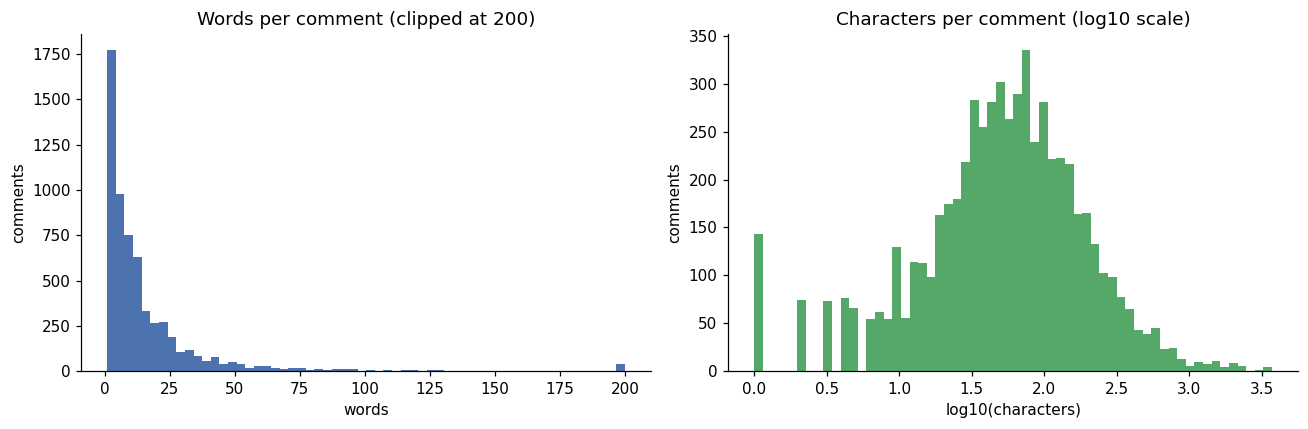

,n_words,n_chars
count,6084.0,6084.0
mean,17.2,110.2
std,32.5,209.4
min,1.0,1.0
25%,4.0,25.0
50%,9.0,55.5
75%,19.0,118.0
90%,37.0,233.0
99%,139.3,864.5
max,601.0,3717.0


Comments with <= 3 words: 1416 (23.3%)


In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(corpus.n_words.clip(upper=200), bins=60, color='#4C72B0')
axes[0].set(title='Words per comment (clipped at 200)', xlabel='words', ylabel='comments')
axes[1].hist(np.log10(corpus.n_chars.clip(lower=1)), bins=60, color='#55A868')
axes[1].set(title='Characters per comment (log10 scale)', xlabel='log10(characters)', ylabel='comments')
plt.tight_layout(); plt.savefig(FIG_DIR / 't1_length_hist.png', bbox_inches='tight'); plt.show()

display(corpus[['n_words', 'n_chars']].describe(percentiles=[.25, .5, .75, .9, .99]).round(1))
print('Comments with <= 3 words:', (corpus.n_words <= 3).sum(), f'({(corpus.n_words <= 3).mean():.1%})')

**Interpretation — comment length.** Lengths are strongly right-skewed: median **9 words** (55 characters), mean 17.2, 90th percentile 37 words, but a maximum of 601 words. **23.3% of comments have 3 words or fewer**, mostly reactions or greetings with little analysable content. This supports a minimum-length filter in Task 2. The long tail matters for later models: a few comments are long enough to exceed short transformer input limits, so the maximum sequence length must be chosen with this distribution in mind.

In [50]:
VAL_PATH = BASE_DIR / 'lang_validation.csv'
if not VAL_PATH.exists():          # never overwrite hand labels
    val = (corpus[corpus.lang_group.isin(['english', 'romanised_sinhala (singlish)'])]
           .groupby('lang_group').sample(n=50, random_state=SEED)
           [['comment_id', 'text_original', 'lang_group']])
    val['human_label'] = ''
    val.to_csv(VAL_PATH, index=False, encoding='utf-8-sig')
    print('Created lang_validation.csv: label it, then run the next cell')
else:
    print('lang_validation.csv already exists: not overwritten')

lang_validation.csv already exists: not overwritten


**Validating the language detector.** The hardest distinction is English vs Singlish, because both use Latin letters. A stratified random sample of 100 comments (50 predicted English, 50 predicted Singlish) was labelled by hand in `lang_validation.csv`. The file is only created if it does not exist, so hand labels are never overwritten.

In [51]:
from sklearn.metrics import classification_report

val = pd.read_csv(BASE_DIR / 'lang_validation.csv')
val['human_label'] = val['human_label'].fillna('').astype(str).str.strip().str.lower()
val['pred'] = val.lang_group.str.startswith('romanised').map({True: 'singlish', False: 'english'})

# Rows the annotator marked as emoji / no language are excluded from scoring
scored = val[val.human_label.isin(['english', 'singlish'])]
print(f'Scored {len(scored)} of {len(val)} hand-labelled comments '
      f'({len(val) - len(scored)} excluded as non-language, e.g. emoji only)')
print(f'Detector accuracy: {(scored.pred == scored.human_label).mean():.3f}\n')
print(classification_report(scored.human_label, scored.pred, digits=3))
pd.crosstab(val.human_label, val.pred)

Scored 99 of 100 hand-labelled comments (1 excluded as non-language, e.g. emoji only)
Detector accuracy: 0.899

              precision    recall  f1-score   support

     english      0.820     0.976     0.891        42
    singlish      0.980     0.842     0.906        57

    accuracy                          0.899        99
   macro avg      0.900     0.909     0.898        99
weighted avg      0.912     0.899     0.900        99



pred,english,singlish
human_label,,
english,41,1
imoji,0,1
singlish,9,48


**Interpretation — detector accuracy.** One sample was emoji-only and is excluded, leaving 99 scored comments. The detector is **about 90% accurate**. Errors are almost all in one direction: **9 Singlish comments were labelled English**, while only 1 English comment was labelled Singlish. So Singlish is detected with high precision but lower recall, and the English group is "contaminated" by roughly 1 Singlish comment in 5. In practice the English share in the corpus is slightly overstated and the Singlish share understated. This supports using multilingual models that do not rely on a perfect language split, rather than separate per-language pipelines.

### Length by language group

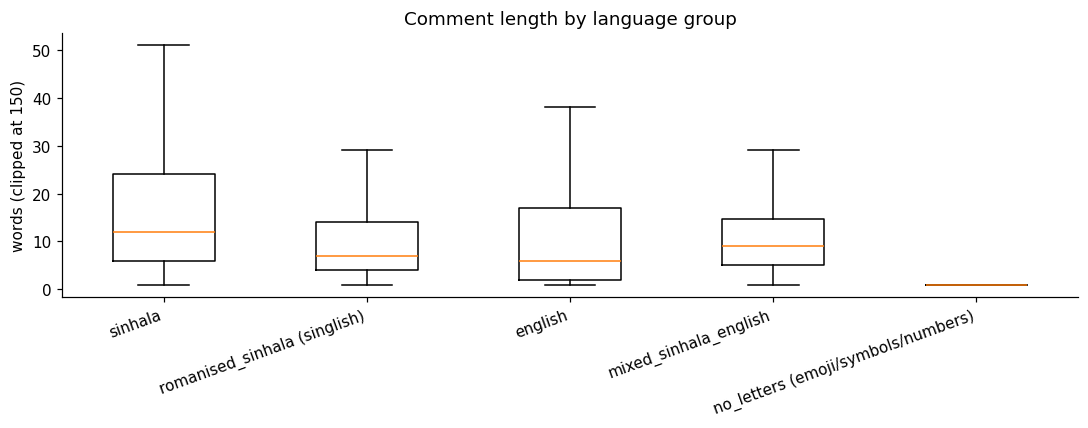

In [52]:
order = corpus.lang_group.value_counts().index
data = [corpus.loc[corpus.lang_group == g, 'n_words'].clip(upper=150) for g in order]
plt.figure(figsize=(10, 4))
plt.boxplot(data, showfliers=False)
plt.xticks(range(1, len(order) + 1), order, rotation=20, ha='right'); plt.ylabel('words (clipped at 150)')
plt.title('Comment length by language group')
plt.tight_layout(); plt.savefig(FIG_DIR / 't1_length_by_lang.png', bbox_inches='tight'); plt.show()

**Interpretation — length by language.** Sinhala-script comments are the longest (median about 12 words) and most varied, which suggests that more detailed arguments are written in Sinhala script. English comments are often very short (many 1–2 word reactions such as *"Thank you"*), and Singlish comments are short and conversational. Emoji-only comments are a single "word" by construction.

### Language distribution

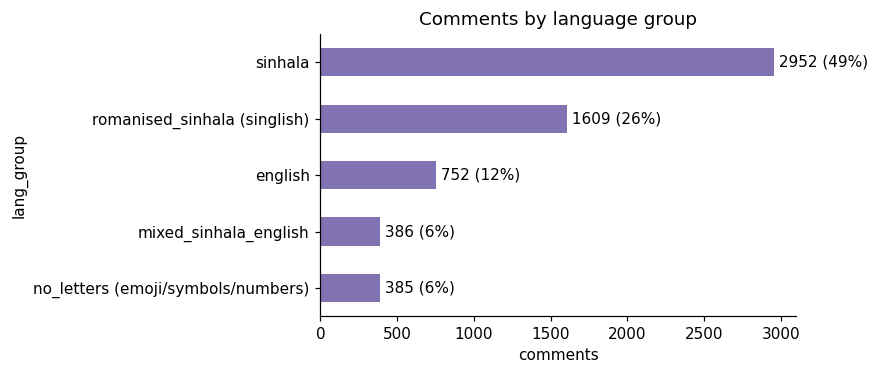

,text_original
lang_group,
english,"[Thank you, Great work sir, Hello teacher , how can I get this?]"
mixed_sinhala_english,"[Meya vitarai අනික් හැමෝම බූරුවන් අගමැති ජනපති නැතුව inne putthalam set, @nadeekaisuranga3974 ඔයා වගේද😅, Link eka ද..."
no_letters (emoji/symbols/numbers),"[🎉🎉🎉🎉🎉, ❤❤❤❤, ❤❤❤❤]"
romanised_sinhala (singlish),"[Demala thiyenne 3weniyata, Pissu ithihasaya …. Mala ilawwa … katada oya bambu onei, Baduw]"
sinhala,"[1වසර 6වසර ව්තරක් නෙමෙයි.අනික් ළමයි ගැනත් හිතුවා නම් වට්නවා.ඔවුන් පීඩනයෙන් පරණ ව්දිහටම., අවුරුදු අද 18 ක විතර දරුව..."


In [53]:
lang_counts = corpus.lang_group.value_counts()
ax = lang_counts.plot.barh(figsize=(8, 3.5), color='#8172B2')
ax.invert_yaxis(); ax.set(title='Comments by language group', xlabel='comments')
for i, v in enumerate(lang_counts):
    ax.text(v, i, f' {v} ({v/len(corpus):.0%})', va='center')
plt.tight_layout(); plt.savefig(FIG_DIR / 't1_language.png', bbox_inches='tight'); plt.show()

# sample comments per group to sanity-check the detector
corpus.groupby('lang_group').text_original.apply(
    lambda s: s.sample(min(3, len(s)), random_state=SEED).tolist()).to_frame()

**Interpretation — language distribution.**

| Group | Comments | Share |
|---|---|---|
| Sinhala script | 2,952 | 48.5% |
| Romanised Sinhala (Singlish) | 1,608 | 26.4% |
| English | 752 | 12.4% |
| Mixed Sinhala–English | 386 | 6.3% |
| Emoji / numbers only | 385 | 6.3% |

Only about 12% of comments are English, and over a quarter are Singlish, which has no standard spelling (e.g. *puluwan / puluwn*). This is the most important EDA finding for the rest of the pipeline: English-only tools are unsuitable, and the tokenisers and models in Tasks 2–4 must handle Sinhala script, romanised Sinhala and code-mixing. This motivates the language strategy chosen in Task 2.

### Comments per video and per channel

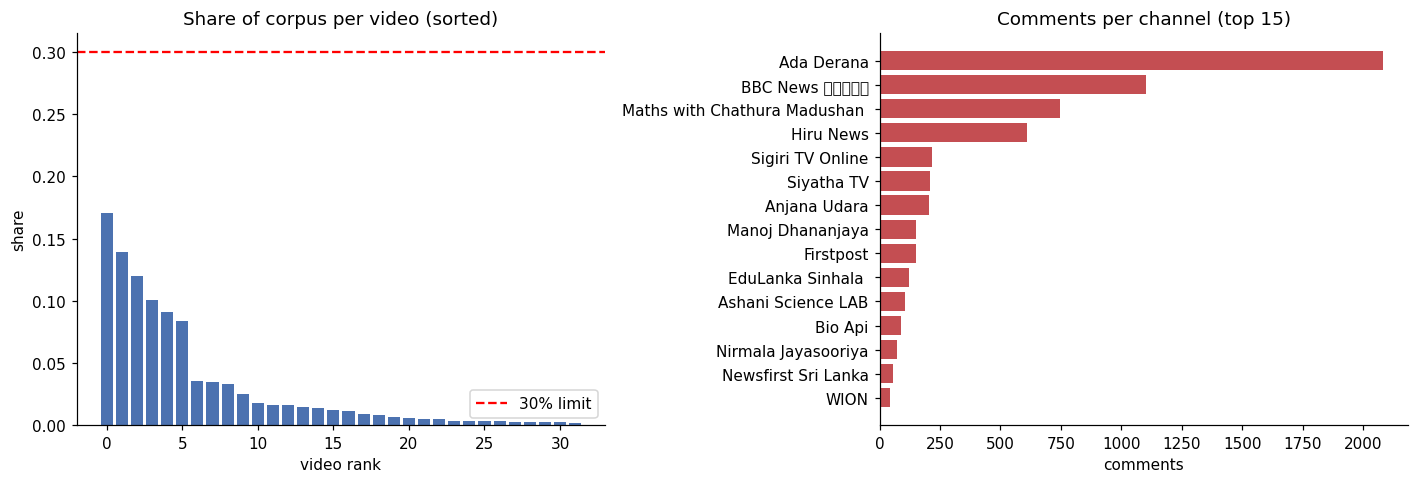

,video_id,channel_title,n,share
0,F-DLnJM7jpg,Ada Derana,1035,0.170118
1,RHfwHM3M9Fc,Ada Derana,845,0.138889
2,-pHFRz2p-Nw,Maths with Chathura Madushan,730,0.119987
3,iKJSiiynAWQ,Hiru News,610,0.100263
4,WoD8P9g8OHs,BBC News සිංහල,552,0.090730
5,Srr-sYiIDuI,BBC News සිංහල,510,0.083826
6,wq5d9IPRnfk,Sigiri TV Online,217,0.035667
7,mFrc4QiqAXE,Siyatha TV,210,0.034517
8,tHmwGBt4k74,Anjana Udara,203,0.033366
9,D02nj8GVQYA,Firstpost,152,0.024984


In [54]:
per_video = corpus.groupby(['video_id', 'channel_title']).size().sort_values(ascending=False).reset_index(name='n')
per_video['share'] = per_video.n / len(corpus)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(range(len(per_video)), per_video.share, color='#4C72B0')
axes[0].axhline(MAX_VIDEO_SHARE, ls='--', c='red', label='30% limit')
axes[0].set(title='Share of corpus per video (sorted)', xlabel='video rank', ylabel='share'); axes[0].legend()

per_channel = corpus.channel_title.value_counts().head(15)
axes[1].barh(per_channel.index[::-1], per_channel.values[::-1], color='#C44E52')
axes[1].set(title='Comments per channel (top 15)', xlabel='comments')
plt.tight_layout(); plt.savefig(FIG_DIR / 't1_per_video_channel.png', bbox_inches='tight'); plt.show()

per_video.head(10)

**Interpretation — distribution across videos and channels.** No video exceeds the 30% limit (largest 17.0%), but the corpus is still concentrated: the **top 6 videos provide about 70% of comments**, and **Ada Derana alone contributes 34%** across its videos, followed by BBC News Sinhala (18%). The corpus is therefore dominated by mainstream news channels and their audiences. Findings in later tasks should be checked for channel bias (for example, whether a theme comes mostly from one channel).

### Language mix per channel

In [55]:
pd.crosstab(corpus.channel_title, corpus.lang_group, margins=True).sort_values('All', ascending=False).head(12)

lang_group,english,mixed_sinhala_english,no_letters (emoji/symbols/numbers),romanised_sinhala (singlish),sinhala,All
channel_title,,,,,,
All,752,386,385,1609,2952,6084
Ada Derana,128,135,78,740,1001,2082
BBC News සිංහල,162,46,99,170,624,1101
Maths with Chathura Madushan,87,74,48,207,332,748
Hiru News,34,48,25,172,331,610
Sigiri TV Online,28,12,6,56,115,217
Siyatha TV,12,16,6,82,94,210
Anjana Udara,32,11,15,31,114,203
Manoj Dhananjaya,17,12,3,35,86,153


**Interpretation — language by channel.** The language mix differs strongly by channel. Sinhala news channels (Ada Derana, BBC Sinhala, Hiru) are mostly Sinhala and Singlish, while **Firstpost** (an Indian English-language channel) is almost entirely English (118 of 152). The English group therefore partly reflects international coverage of the textbook controversy rather than local opinion, which is worth remembering when comparing language groups.

### Comments over time

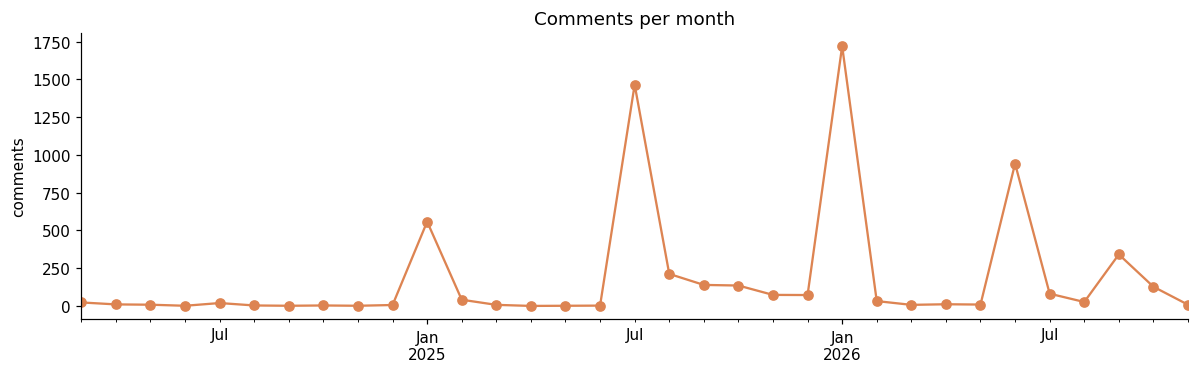

In [56]:
monthly = corpus.set_index('comment_published_at').resample('MS').size()
ax = monthly.plot(figsize=(11, 3.5), marker='o', color='#DD8452')
ax.set(title='Comments per month', xlabel='', ylabel='comments')
plt.tight_layout(); plt.savefig(FIG_DIR / 't1_timeline.png', bbox_inches='tight'); plt.show()

**Interpretation — timeline.** Comment activity is **event-driven, not continuous**: almost nothing appears between peaks. The main peaks (July 2025, January 2026, June 2026) coincide with the publication of the largest videos in the corpus — the O/L syllabus change explainer, the Ada Derana discussion on why the reforms were halted, and the Ada Derana exam notice. Discussion is therefore driven by announcements and news coverage, and the corpus reflects reactions to specific events rather than steady public debate. Comments made after the collection date (20 November 2026) are not included.

### Top English words and word pairs (charts)

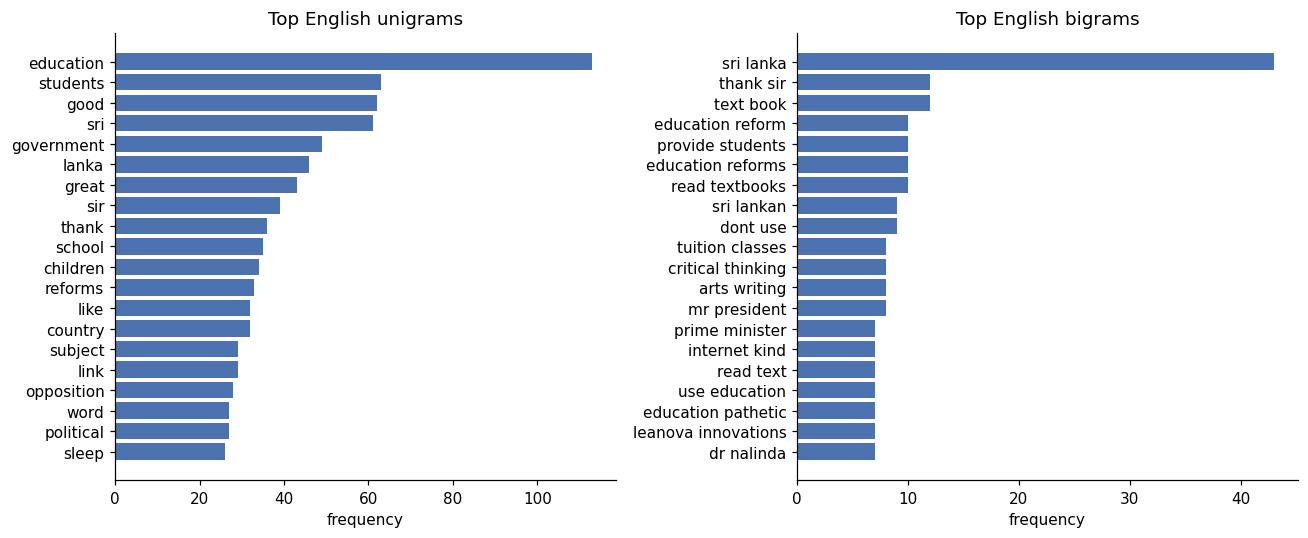

In [57]:
# EDA-only tokeniser: keeps Sinhala words whole, including vowel signs and the zero-width joiner (U+200D) in ශ්‍රී etc.
TOKEN_RE = re.compile(r"[\u0D80-\u0DFF\u200D]+|[a-z][a-z']+")
SI_STOP = {'සහ', 'හා', 'ද', 'නම්', 'ඒ', 'මේ', 'එක', 'එකක්', 'නෑ', 'නැහැ', 'කියලා', 'වගේ', 'තමයි', 'ඔයා', 'අපි', 'මම',
           'නිසා', 'තියෙන්නේ', 'ගැන', 'වෙන්න', 'කරන්න', 'එහෙම', 'මෙහෙම', 'තව', 'ඉතින්', 'හරි', 'නේ', 'ය', 'යි', 'වත්', 'දැන්'}
URL_RE = re.compile(r'https?://\S+|www\.\S+')
STOP = set(ENGLISH_STOP_WORDS) | SI_STOP | SINGLISH_MARKERS

def eda_tokens(text):
    t = URL_RE.sub(' ', str(text).lower())
    return [w for w in TOKEN_RE.findall(t) if w not in STOP and len(w) > 1]

def top_ngrams(texts, n=1, k=20):
    c = Counter()
    for t in texts:
        toks = eda_tokens(t)
        c.update(zip(*[toks[i:] for i in range(n)]))
    return pd.DataFrame([(' '.join(g), f) for g, f in c.most_common(k)], columns=['ngram', 'freq'])

groups = {'english': corpus.lang_group == 'english',
          'sinhala': corpus.lang_group == 'sinhala',
          'romanised_sinhala': corpus.lang_group.str.startswith('romanised'),
          'mixed': corpus.lang_group == 'mixed_sinhala_english'}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, n in zip(axes, (1, 2)):
    df_ng = top_ngrams(corpus.loc[groups['english'], 'text_original'], n=n)
    ax.barh(df_ng.ngram[::-1], df_ng.freq[::-1], color='#4C72B0')
    ax.set(title=f'Top English {"unigrams" if n == 1 else "bigrams"}', xlabel='frequency')
plt.tight_layout(); plt.savefig(FIG_DIR / 't1_english_ngrams.png', bbox_inches='tight'); plt.show()

**Interpretation — English n-grams.** Content words point to the main concerns: *education, students, government, children, reforms, opposition, political*. Bigrams such as **"text book", "read textbooks", "internet kind", "link", "word"** refer to the Grade 6 module controversy (an inappropriate website link printed in a textbook), and **"tuition classes", "critical thinking", "arts writing"** point to debates about exam culture and skills. Politeness terms (*thank sir, great*) come from explainer videos. *"leanova innovations"* looks like a promotional repeat and should be checked in Task 2.

### Top Sinhala / Singlish / mixed words (tables, because charts can't draw Sinhala letters properly)

In [58]:
tables = []
for g in ['sinhala', 'romanised_sinhala', 'mixed']:
    if groups[g].sum() == 0:
        continue
    for n in (1, 2):
        t = top_ngrams(corpus.loc[groups[g], 'text_original'], n=n, k=15)
        t.columns = pd.MultiIndex.from_product([[f'{g} {"uni" if n == 1 else "bi"}gram'], t.columns])
        tables.append(t)
pd.concat(tables, axis=1)

sinhala unigram               sinhala bigram       \
             ngram freq                   ngram freq   
0             නැති  263               ඉගෙන ගන්න   53   
1              කරන  255                උසස් පෙළ   38   
2             ගන්න  237  අධ්‍යාපන ප්‍රතිසංස්කරණ   37   
3         අධ්‍යාපන  229                 අපේ රටේ   29   
4               ඒක  222                පාසල් වල   29   
5             ඉන්න  216         අධ්‍යාපන ක්‍රමය   29   
6               ඕන  211              විය යුතුයි   26   
7              අපේ  210                වැඩ බැරි   26   
8              මේක  205     බැරි පොල්බුරුවෙකුගේ   24   
9               වල  204   පොල්බුරුවෙකුගේ විලාපය   24   
10             වලට  198              විලාපය මෙය   24   
11             එපා  198                මෙය කාලය   24   
12              ඔය  191             කාලය නාස්ති   24   
13           පාසල්  190          නාස්ති කිරීමක්   24   
14             රටේ  189            කිරීමක් පමණි   24   

   romanised_sinhala unigram      romanised_sinhala bigram      mixed unigram  \
                       ngram freq                    ngram freq         ngram   
0                         na  140            kisima rataka   30      syllabus   
1                      pissu   83              links danne   29       english   
2                        sir   67            mulinma buddy   28           එකට   
3                        dan   65                buddy net   28            ඒක   
4                        ane   62            thoge mulinma   27          exam   
5                         ne   62               net deepan   27           වලට   
6                    subject   60              deepan moda   27         අලුත්   
7                       rate   59              moda haraka   27           නේද   
8                       inna   57             haraka links   27           එකේ   
9                      danne   56             danne kisima   27       subject   
10                       epa   55           rataka thopita   27         grade   
11                      hari   55            thopita pissu   27         maths   
12                       ona   52              pissu unata   27       ඉතිහාසය   
13                       nam   52               unata rate   27            ඕන   
14                      moda   51            rate okkotama   27           තමා   

                mixed bigram       
   freq                ngram freq  
0    34       english medium   11  
1    28   maths withchathura    8  
2    25       අලුත් syllabus    8  
3    21             exam එකට    6  
4    20              වසරට යන    4  
5    20              ගන්න ඕන    4  
6    19  lucifer secretagent    4  
7    18              ජය වේවා    4  
8    18            වැඩක් ඇති    4  
9    17          npp germany    4  
10   17      comment section    4  
11   16            ඉගෙන ගන්න    3  
12   16            මේක බලන්න    3  
13   16       syllabus අලුත්    3  
14   16       syllabus grade    3

**Interpretation — Sinhala, Singlish and mixed n-grams.**
- **Sinhala unigrams** are dominated by function words (*නැති, කරන, ගන්න, ඒක, ඕන*), which shows the small hand-made Sinhala stopword list is incomplete; Task 2 needs a fuller list or a frequency-based approach. Meaningful bigrams include **අධ්‍යාපන ප්‍රතිසංස්කරණ** (education reforms), **අධ්‍යාපන ක්‍රමය** (education system), **උසස් පෙළ** (A/L), **පාසල් වල** (in schools) and **අපේ රටේ** (in our country). One repeated insulting comment produces a chain of bigrams (*වැඩ බැරි … කාලය නාස්ති කිරීමක් පමණි*), showing how a single duplicated text distorts frequency counts.
- **Singlish** bigrams are dominated by the **Buddy Net link spam** (*buddy net, links danne, kisima rataka*), again showing the need for spam removal. Unigrams such as *subject, sir, pissu* (crazy) show both practical questions and hostile language.
- **Mixed** comments use English for technical terms inside Sinhala sentences: *syllabus, subject, grade, exam, maths, english medium, අලුත් syllabus* (new syllabus), and **ඉතිහාසය** (history), linked to the debate about the history subject. This code-switching pattern is typical of the corpus and must be preserved by the tokenisers in Task 2.

## Task 1 summary and limitations

**Requirements met:** 6,083 unique public comments collected with YouTube Data API v3, from 32 videos across 21 channels; largest video 17.0% (< 30%); videos with comments disabled excluded; full metadata and collection log saved; unmodified raw file preserved; EDA completed before preprocessing.

**Key findings that shape the next tasks**
1. The corpus is **multilingual and informal**: 48.5% Sinhala script, 26.4% Singlish, 12.4% English, 6.3% mixed, 6.3% emoji-only → multilingual tokenisers and models are needed (Task 2–4).
2. Comments are **short** (median 9 words; 23% ≤ 3 words) → a minimum-length filter is needed, and short texts will limit theme and classification quality.
3. **Spam and duplicates** (Buddy Net link spam, repeated insults, 374 duplicate texts) distort frequency statistics → removal in Task 2.
4. Discussion is **event-driven** and concentrated in **news channels** (Ada Derana 34%).

**Limitations of the data collection**
- YouTube search ranking is opaque and personalised to region and language, so the videos are not a random sample of all reform discussion.
- Manual video selection involves judgement; it is documented to make it transparent and repeatable.
- Tamil is excluded by design, so Tamil-speaking communities are not represented.
- The language detector is about 90% accurate and tends to label Singlish as English.
- The API does not return deleted or held comments, and comments posted after 20 November 2026 are missing.
- YouTube commenters are not representative of parents, teachers or students in general (discussed further in Task 6).

In [59]:
# Programmatic deletion of the excluded NDTV video checkpoint file to freeze correct raw state
ndtv_ckpt = CKPT_DIR / 'WbiLX0VRmF0.json'
if ndtv_ckpt.exists():
    ndtv_ckpt.unlink()
    print('Removed excluded NDTV video checkpoint from raw storage.')

inc = videos[videos.include].sort_values('comment_count', ascending=False)
for _, v in inc.iterrows():
    sample = raw.loc[raw.video_id == v.video_id, 'text_original'].head(3).str.slice(0, 80).tolist() if 'raw' in globals() else ['Raw data not loaded yet']
    print(f"{v.video_id} | {v.channel_title} | {v.comment_count:.0f}\n   {v.title}\n   e.g. {sample}\n")

Removed excluded NDTV video checkpoint from raw storage.
F-DLnJM7jpg | Ada Derana | 1030
   O/L, A/L සහ ශිෂ්‍යත්ව විභාගය ගැන දැනුම්දීමක් | Ada Derana
   e.g. ['Kimbi ammandi', 'wesagana puujita shreegabalpradha', '😂 ඔහොම හොදට ලයාන්විතව කතා කරාට මිනිහවත් බව කරන් ඇති']

RHfwHM3M9Fc | Ada Derana | 845
   අධ්‍යාපන ප්‍රතිසංස්කරණ ඇත්තටම අකුල ගත්තේ ඇයි | Ada Derana
   e.g. ['👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍👍❤❤❤❤❤❤❤❤❤❤', 'නලින්ද සහෝදරයා ඕවා අනිවාර්යයෙන්ම සංවාදයට ගත යුතුයි.\n❤❤❤', 'කොට කලිසම් ඇදගෙන දුවන පනින, උගුරු දණ්ඩවත් පැනලා නැත වයසකදි වෘත්තීය අධ්\u200dයාපනය තෝර']

-pHFRz2p-Nw | Maths with Chathura Madushan  | 728
   2026 O/L Syllabus Change – Subject 7යි Credit 18යි | අලුත් විෂය ක්‍රමය මෙන්න
   e.g. ['මෙන්න අලුත් 6 වසර syllabus  එක👇👇👇👇👇👇👇👇👇👇\nhttps://youtu.be/InbNPEMbLgM', 'සමලිංගික විෂය නැද්ද', '2028 O/L අයටත් ඔක සෙට් වෙනවද']

iKJSiiynAWQ | Hiru News | 608
   2026 සිට අධ්‍යාපනයට වෙන්න යන වෙනස - Hiru News
   e.g. ['2012 ලමයින්ටයි හැම දාම අසාධාරනේ 5 වසරෙ පෙපර් 1,2 කොටස

## Task 2

### 2.1 Setup

In [60]:
!pip -q install emoji

import html, unicodedata, time
import emoji
import transformers
from transformers import AutoTokenizer

PROC_DIR = BASE_DIR / 'data' / 'processed'
PROC_DIR.mkdir(parents=True, exist_ok=True)

print('emoji       ', emoji.__version__)
print('transformers', transformers.__version__)

df = pd.read_csv(RAW_DIR / 'corpus_selected_raw_text.csv', dtype={'comment_id': str, 'parent_id': str})
df['text_original'] = df.text_original.fillna('').astype(str)
print('Comments loaded:', len(df))

emoji        2.16.0
transformers 5.22.1
Comments loaded: 6084


### 2.2 Cleaning rules

In [61]:
ZW_REMOVE   = re.compile('[​‎‏‪-‮⁠﻿]')   # keep ‌ and ‍ (Sinhala)
URL_RE2     = re.compile(r'(https?://\S+|www\.\S+|\b[\w\-]+\.(?:com|lk|net|org|io|me|ly|be)(?:/\S*)?)', re.I)
MENTION_RE  = re.compile(r'(?<![\w@])@[^\s@]+')
LEAD_MENTION_RE = re.compile(r'^(?:\s*@user\b[\s,:]*)+')
EMAIL_RE    = re.compile(r'\b[\w.+-]+@[\w-]+\.[\w.]+\b')
PHONE_RE    = re.compile(r'(?<!\d)(?:\+?94[\s-]?|0)7\d[\s-]?\d{3}[\s-]?\d{4}(?!\d)')
MSG_APP_RE  = re.compile(r'wa\.me|t\.me/|whatsapp|whats app|telegram|viber', re.I)
TIME_RE     = re.compile(r'(?<![\d:])\d{1,2}:\d{2}(?::\d{2})?(?![\d:])')
HASHTAG_RE  = re.compile(r'#(\w+)')
LAT_REPEAT  = re.compile(r'([A-Za-z])\1{2,}')
SI_REPEAT   = re.compile(r'([඀-෿])\1{2,}')
PUNCT_REPEAT = re.compile(r'([!?,;:*~_\-])\1+')
DOTS_RE     = re.compile(r'\.{4,}')
SPACE_RE    = re.compile(r'\s+')

def collapse_emoji_runs(text):
    # keep one emoji from each run of the same emoji (spaces between copies also count as a run)
    out, last_end, last_emoji = [], 0, None
    for m in emoji.emoji_list(text):
        gap = text[last_end:m['match_start']]
        if last_emoji == m['emoji'] and gap.strip() == '':
            last_end = m['match_end']
            continue
        out.append(gap); out.append(m['emoji'])
        last_end, last_emoji = m['match_end'], m['emoji']
    out.append(text[last_end:])
    return ''.join(out)

def is_contact_or_promo(text):
    return bool(EMAIL_RE.search(text) or PHONE_RE.search(text) or MSG_APP_RE.search(text))

def clean_text(text):
    t = html.unescape(str(text))
    t = unicodedata.normalize('NFC', t)
    t = ZW_REMOVE.sub('', t)
    t = EMAIL_RE.sub(' ', t)                 # emails are removed before mention detection
    t = URL_RE2.sub(' http ', t)
    t = MENTION_RE.sub('@user', t)
    t = LEAD_MENTION_RE.sub('', t)
    t = HASHTAG_RE.sub(r'\1', t)
    t = TIME_RE.sub(' ', t)
    t = LAT_REPEAT.sub(r'\1\1', t)
    t = SI_REPEAT.sub(r'\1', t)
    t = PUNCT_REPEAT.sub(r'\1', t)
    t = DOTS_RE.sub('...', t)
    t = collapse_emoji_runs(t)
    return SPACE_RE.sub(' ', t).strip()

EXAM_NORMALISE = [
    (re.compile(r'\b([oa])\s*[/\\.]\s*l\b', re.I), lambda m: m.group(1).lower() + '/l'),
    (re.compile(r'සා\s*[/\\.]\s*පෙළ'), 'සාමාන්‍ය පෙළ'),
    (re.compile(r'උ\s*[/\\.]\s*පෙළ'), 'උසස් පෙළ'),
]

def normalise_text(text_clean):
    t = emoji.replace_emoji(text_clean, replace=' ')
    t = re.sub(r'@user|\bhttp\b', ' ', t)
    for pat, rep in EXAM_NORMALISE:
        t = pat.sub(rep, t)
    return SPACE_RE.sub(' ', t.lower()).strip()

# quick demonstration on made-up examples
demo = ['​@Some-User123 Sooooo goooood!!!! ❤❤❤❤ 😂😂',
        'O.L ලියන අයට මේක හොඳයි 👍👍👍 https://youtu.be/abc #EducationReform',
        'Class join karanna 0771234567 ta whatsapp karanna',
        'සා/පෙළ විෂය 7ට අඩු කරනවා..... 12:45 බලන්න']
for d in demo:
    c = clean_text(d)
    print(f'RAW  : {d}\nCLEAN: {c}\nNORM : {normalise_text(c)}\ncontact/promo: {is_contact_or_promo(d)}\n')

RAW  : ​@Some-User123 Sooooo goooood!!!! ❤❤❤❤ 😂😂
CLEAN: Soo good! ❤ 😂
NORM : soo good!
contact/promo: False

RAW  : O.L ලියන අයට මේක හොඳයි 👍👍👍 https://youtu.be/abc #EducationReform
CLEAN: O.L ලියන අයට මේක හොඳයි 👍 http EducationReform
NORM : o/l ලියන අයට මේක හොඳයි educationreform
contact/promo: False

RAW  : Class join karanna 0771234567 ta whatsapp karanna
CLEAN: Class join karanna 0771234567 ta whatsapp karanna
NORM : class join karanna 0771234567 ta whatsapp karanna
contact/promo: True

RAW  : සා/පෙළ විෂය 7ට අඩු කරනවා..... 12:45 බලන්න
CLEAN: සා/පෙළ විෂය 7ට අඩු කරනවා... බලන්න
NORM : සාමාන්‍ය පෙළ විෂය 7ට අඩු කරනවා... බලන්න
contact/promo: False

